# 02 – Modellering og resultater

Livssyklus-steg: **Modelling** (baselines → utforske modeller → finjustere → evaluere og analysere feil) og **Deployment** (overvåking).

Notatboka viser resultatene fra skriptene. Selve beregningene ligger i `scripts/` slik at de kan reproduseres med `run_all.sh`:

| Skript | Hva |
|---|---|
| `train.py` | baselines, random search med gruppert kryssvalidering, modellvalg og terskler (bare train_core og val) |
| `analyze_val.py` | feilanalyse, permutation importance og læringskurve (val) |
| `evaluate_test.py` | én endelig testkjøring |
| `monitor.py` | simulert overvåking per måned |

In [1]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 160)
val = json.load(open('../reports/val_model_comparison.json'))
search = json.load(open('../reports/search_results.json'))
meta = json.load(open('../models/metadata.json'))

## 1. Modellsammenligning på valideringsdata
Alle modeller er trent på train_core (+ utvidede legitime prefikser) med hyperparametere fra random search (3-fold `GroupKFold`, gruppert på nettsted).

In [2]:
rows = []
for name, m in val['models'].items():
    rows.append({'modell': name, 'ROC-AUC': m['roc_auc'], 'AP': m['average_precision'],
                 'recall@1%FPR': m['recall_at_fpr_0.01'], 'FPR ekte forsider': m['fpr_real_benign_root'],
                 'FPR korte stier': m['fpr_real_benign_depth1'], 'recall forsider': m['recall_root_phish'],
                 'recall med sti': m['recall_nonroot_phish'], 'MB': m.get('size_mb'), 'ms/URL': m.get('latency_ms')})
display(pd.DataFrame(rows).set_index('modell').round(3))
display(Markdown(f"**Valgt modell:** `{val['selection']['chosen']}`. Regel: størst recall ved 1 % FPR blant modeller ≤ 50 MB og ≤ 100 ms. Ved likhet innenfor 0,01 vinner færrest falske alarmer på ekte forsider."))
print('Regelbasert baseline ved sitt eget flagg:', {k: round(v, 3) for k, v in val['models']['baseline_rules']['rules_at_flag'].items() if isinstance(v, float)})

,ROC-AUC,AP,recall@1%FPR,FPR ekte forsider,FPR korte stier,recall forsider,recall med sti,MB,ms/URL
modell,,,,,,,,,
baseline_dummy,0.500,0.238,0.000,0.000,0.000,0.000,0.000,NaN,NaN
baseline_rules,0.603,0.362,0.000,0.000,0.000,0.000,0.000,NaN,NaN
logistic_regression,0.849,0.793,0.455,0.023,0.009,0.584,0.356,0.003,0.510
decision_tree,0.867,0.810,0.568,0.038,0.015,0.682,0.487,0.074,0.290
random_forest,0.907,0.848,0.591,0.051,0.013,0.727,0.487,8.624,24.995
hist_gradient_boosting,0.888,0.845,0.617,0.047,0.017,0.728,0.536,0.475,2.742


**Valgt modell:** `hist_gradient_boosting`. Regel: størst recall ved 1 % FPR blant modeller ≤ 50 MB og ≤ 100 ms. Ved likhet innenfor 0,01 vinner færrest falske alarmer på ekte forsider.

Regelbasert baseline ved sitt eget flagg: {'threshold': 0.5, 'precision': 0.789, 'recall': 0.226, 'f1': 0.351, 'fpr': 0.019}


In [3]:
pd.DataFrame(search).T

,best_params,best_cv_roc_auc,seconds
logistic_regression,{'logisticregression__C': 0.0745934328572655},0.979696,7
decision_tree,"{'max_depth': 29, 'min_samples_leaf': 75}",0.977482,19
random_forest,"{'min_samples_leaf': 3, 'max_features': 'sqrt'...",0.984626,114
hist_gradient_boosting,"{'l2_regularization': 9.307782732027235, 'lear...",0.989955,561


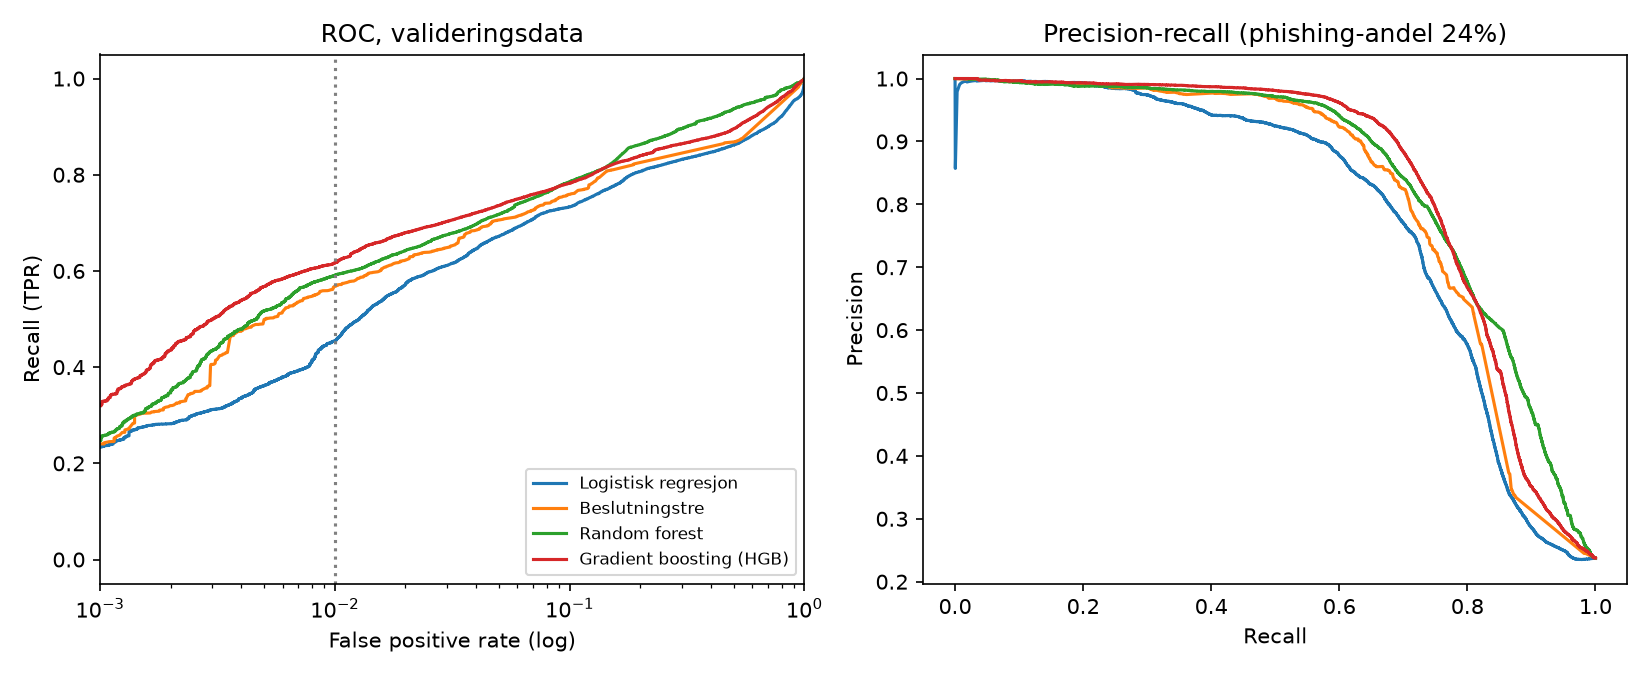

In [4]:
display(Image('../reports/figures/val_roc_pr.png'))

## 2. Terskler og konsekvenser
Terskler velges på valideringsdata: *Høy risiko* ved 1 % FPR og *Mistenkelig* ved 5 % FPR. Forventet presisjon ved lavere andel phishing følger av Bayes' regel: PPV = TPR·π / (TPR·π + FPR·(1−π)).

{'high': 0.55, 'low': 0.13}

{'threshold': 0.55,
 'tp': 18043,
 'fp': 938,
 'tn': 93027,
 'fn': 11230,
 'precision': 0.9505821611084769,
 'recall': 0.6163700338195607,
 'f1': 0.7478343764247523,
 'fpr': 0.009982440270313414}

{'50%': 0.9840625834761515, '5%': 0.7646925555945987, '1%': 0.3841193367463028}

{'benign': {'high': 0.01, 'low': 0.9514, 'suspicious': 0.0387},
 'phish': {'high': 0.6164, 'low': 0.2658, 'suspicious': 0.1178}}

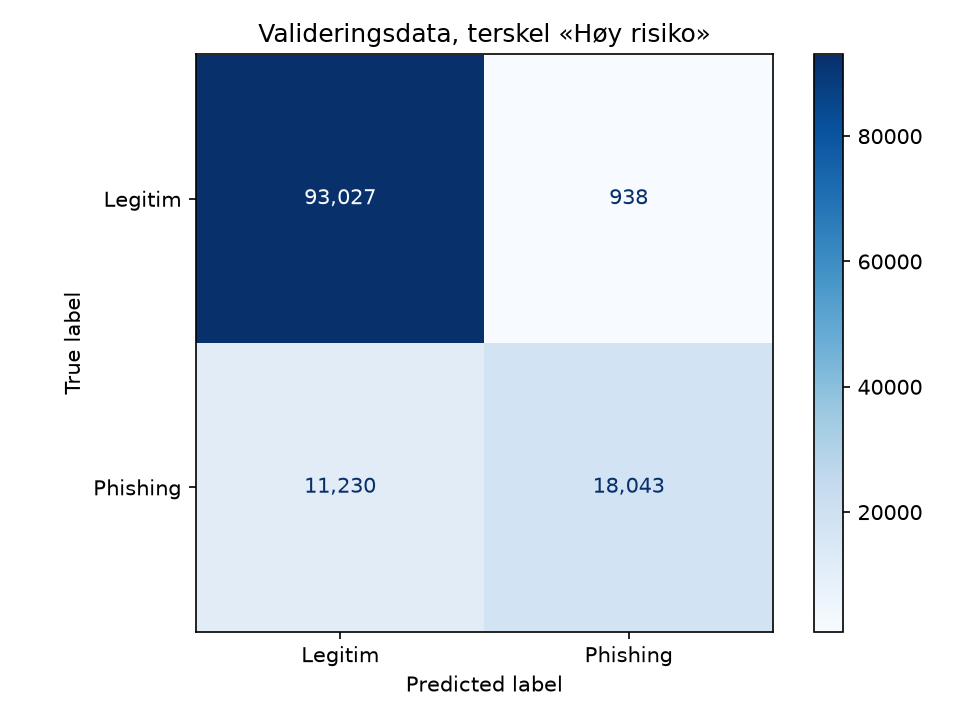

In [5]:
va = json.load(open('../reports/val_analysis.json'))
display(meta['thresholds'], va['val_at_t_high'], va['expected_precision_at_base_rate'], va['band_share_by_class'])
display(Image('../reports/figures/val_confusion_matrix.png'))

## 3. Feilanalyse og feature importance (val)

In [6]:
for k in ['by_shared_platform', 'by_is_root', 'by_tld', 'recall_by_target']:
    display(Markdown(f'**{k}**')); display(pd.DataFrame(va[k]).T)

**by_shared_platform**

,n_benign,fpr,n_phish,recall
false,93041.0,0.0076,23814.0,0.5317
true,924.0,0.2522,5459.0,0.9859


**by_is_root**

,n_benign,fpr,n_phish,recall
false,88279.0,0.0076,17075.0,0.5364
true,5686.0,0.0475,12198.0,0.7283


**by_tld**

,n_benign,fpr,n_phish,recall
app,83.0,0.1446,2719.0,0.9875
ca,526.0,0.0038,39.0,0.5897
co.jp,1363.0,0.0000,7.0,0.0000
co.uk,1733.0,0.0023,132.0,0.5152
com,62364.0,0.0079,15255.0,0.4955
com.au,1088.0,0.0009,28.0,0.2857
edu,1444.0,0.0000,12.0,0.0000
gov,3031.0,0.0000,270.0,0.0000
io,361.0,0.1053,508.0,0.8642
it,1013.0,0.0030,43.0,0.5814


**recall_by_target**

,n,recall
booking,3262.0,0.8743
facebook,2632.0,0.8503
meta,2142.0,0.9599
microsoft,618.0,0.9029
naver,3197.0,0.5327
other,2357.0,0.9415
outlook,489.0,0.9632
qmp,437.0,0.0000
rakuten,535.0,0.4467
robinhood,4604.0,0.0382


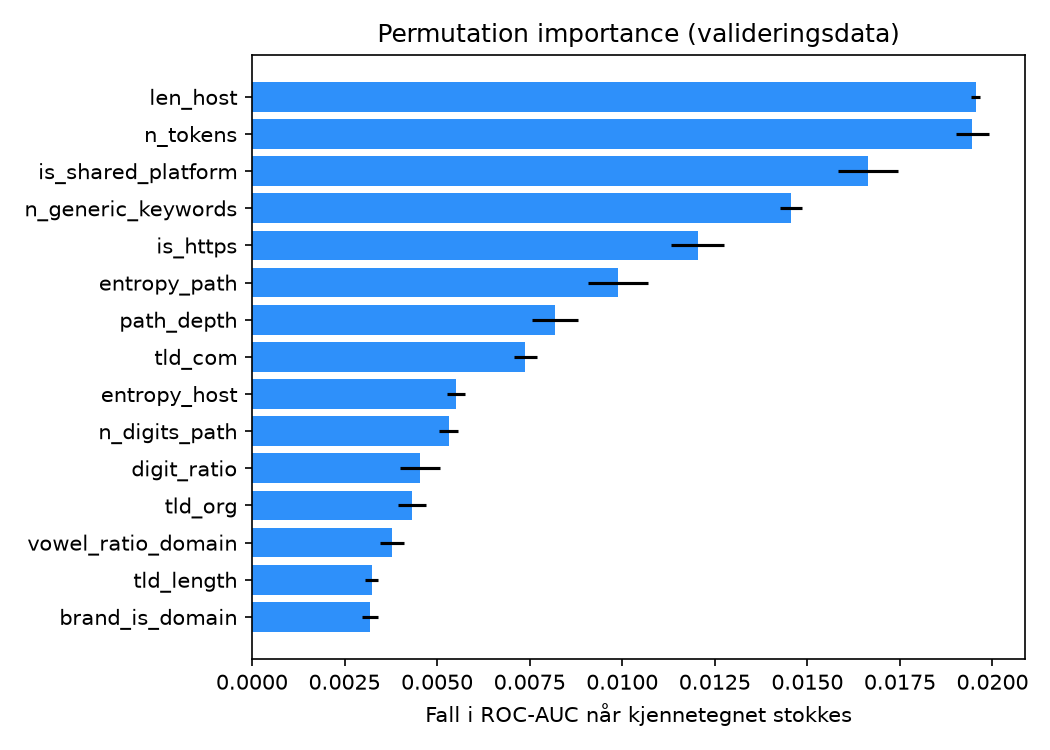

In [7]:
display(Image('../reports/figures/permutation_importance.png'))

De verste feilene (defanged) står i `reports/val_errors.md`.

In [8]:
display(Markdown(open('../reports/val_errors.md').read()))

# Feilanalyse, valideringsdata

URL-ene er «defanged» (hxxp, [.]) så de ikke blir klikkbare.

## 25 legitime URL-er med høyest score (falske positive)

| score | url |
|---|---|
| 1.000 | `hxxps://docs[.]google[.]com/document/d/1bbwkcx6Ry9XnPCrMVwat7V8kCLiO0i-5x-a_m1BE8a4/edit` |
| 1.000 | `hxxps://basketballstarsonline[.]github[.]io/` |
| 1.000 | `hxxps://v3-east-streameast-v3[.]pages[.]dev/` |
| 0.999 | `hxxps://magicmind-by-whiteboard[.]webflow[.]io/` |
| 0.999 | `hxxps://dungeonmastertools[.]github[.]io/items[.]html` |
| 0.999 | `docs[.]google[.]com/presentation/d/1H5oCYPFmvWXJj2QD-VzlIDxsVJ4_2pdKpqQoHFYbRHw/edit` |
| 0.999 | `hxxps://officesupportjp[.]github[.]io/blog/cl0m8t2dj00393gvs3r7oar2m/` |
| 0.999 | `hxxps://disabilitysolutions-s2s[.]netlify[.]app/` |
| 0.999 | `swiftly-savemart[.]vercel[.]app/` |
| 0.999 | `hxxps://canadiantire-timeline[.]netlify[.]app/` |
| 0.999 | `hxxps://docs[.]google[.]com/document/d/1GATps3bQQ0Fomun7Vxne58zNKMkgzPGc-Uq-7QxGRFk/edit` |
| 0.999 | `hxxps://oldpixlr[.]netlify[.]app/x/` |
| 0.999 | `hxxps://alliecprojects[.]netlify[.]app/` |
| 0.999 | `hxxps://kiyokosmacros[.]netlify[.]app/` |
| 0.999 | `hxxps://onlymegaleaks[.]netlify[.]app/` |
| 0.998 | `hxxps://hippie-chicks-catering[.]square[.]site/` |
| 0.998 | `widget[.]suphelper[.]top/` |
| 0.998 | `hxxps://docs[.]google[.]com/spreadsheets/d/1wzy1VxNWEAAc0FQyDAdpiFggAfn5U6RGPp2CisAHZW8` |
| 0.998 | `hxxps://wildflowerconnectionspeoriaaz[.]squarespace[.]com/` |
| 0.998 | `hxxps://raesvirtualdesk[.]my[.]canva[.]site/` |
| 0.998 | `hxxp://awesomexxx[.]top/` |
| 0.997 | `hxxps://g3f8e15190c6edd-qcomalldb01[.]adb[.]ap-mumbai-1[.]oraclecloudapps[.]com/ords/r/him01/quicklog/login` |
| 0.997 | `hxxps://gsheets-formula-generator[.]bubbleapps[.]io/answer-generator` |
| 0.997 | `hxxp://bvsdd[.]weebly[.]com/` |
| 0.997 | `zp1v56uxy8rdx5ypatb0ockcb9tr6a-oci3--5173--c8c182a3[.]local-credentialless[.]webcontainer-api[.]io/[.]localservice@no-server[.]c8c182a3[.]html` |

## 25 phishing-URL-er med lavest score (falske negative)

| score | target | url |
|---|---|---|
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/_Robinhood%20Dispute%20%20Step-by-Step%20Process%20~_!!_%20%20%20Challenge%20a%20Transaction%20%20[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/How%20do%20I%20speak%20to%20a%20human%20at%20Robinhood[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/Can%20Robinhood%20Reverse%20a%20Transaction_%20%F0%9F%A4%94%F0%9F%92%B3%2B1%F0%9F%8C%99866%F0%9F%8C%99240%F0%9F%8C%990466[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/How%20do%20I%20send%20a%20message%20on%20Robinhood[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/%E3%80%90Connect~USA%E3%80%91How%20to%20Enable%20Two-Factor%20Authentication%20on%20Robinhood_[.]pdf` |
| 0.000 | robinhood | `hxxps://ctl[.]gatech[.]edu/sites/default/files/webform/teaching_with_technology_partner/9018/How_Do_I_Talk_Directly_on_Robinhood[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/how%20to%20withdraw%20from%20robinhood%20%E3%80%90%F0%9F%93%9E%20Call~Now%E2%84%A2%E3%80%91[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/Can%20You%20Talk%20to%20Someone%20on%20Robinhood_%20%7B%7BHere%E2%80%99s%20What%20You%20Need%20to%20Know%7D%7D[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/how%20to%20withdraw%20from%20robinhood%20%7BRobinhood%20Service%7D[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/How%20do%20I%20speak%20directly%20to%20Robinhood%20Calling%20Help[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/How%20do%20I%20message_0[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/How_do_I_talk_directly_on_Robinhood[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/Does%20Robinhood%20Have%2024[.]pdf` |
| 0.000 | robinhood | `hxxps://ctl[.]gatech[.]edu/sites/default/files/webform/teaching_with_technology_partner/9860/How%20do%20I%20talk%20to%20Robinhood%20customer[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/How%20do%20I%20talk%20to%20Robinhood%20customer%20call[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/%7BAsk~Expert%7D%20How%20to%20enable%20Two-Factor%20Authentication%20on%20Robinhood_[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/How%20long%20does%20robinhood%20take%20to%20respond_1[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/How%20to%20speak%20directly%20in%20Robinhood%20speak_0[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/How_to_reverse_a_transaction_on_Robinhood[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/How%20do%20you%20communicate%20with%20Robinhood%20%7B%7BCaLL~nOw%7D%7D%20(2)[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/how%20do%20i%20withdraw%20money%20from%20robinhood%20%7BRobinhood%20Service%7D[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/How_to_reverse_a_transaction_on_Robinhood_Full_Guide[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/tdrhtrgtrgrgr[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/Does%20Robinhood%20have%20a%20live%20chat%20%7B%7Blive~call%7D%7D[.]pdf` |
| 0.000 | robinhood | `hxxps://amtrakoig[.]gov/sites/default/files/webform/foia_form/_sid_/fdgvesr[.]pdf` |


## 4. Læringskurve
Hvor mye bedre blir modellen med mer data? Andelen nettsteder fra train_core varieres, og ytelsen måles på val.

,share_of_sites,train_rows,val_roc_auc,val_recall_at_fpr_0.01
0,0.05,28827,0.868122,0.561507
1,0.10,59639,0.879881,0.574283
2,0.25,136376,0.871566,0.598333
3,0.50,301654,0.877275,0.599631
4,1.00,598981,0.888492,0.616882


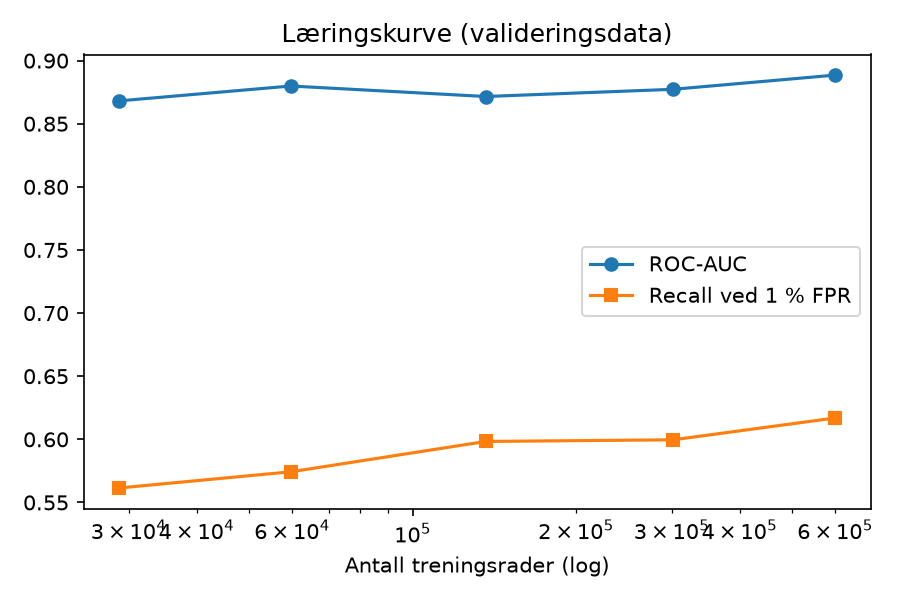

In [9]:
display(pd.DataFrame(va['learning_curve']))
display(Image('../reports/figures/learning_curve.png'))

## 5. Endelig test (modell v2)
Testdata: september–desember 2025, ikke brukt til trening, modellvalg eller terskler. Benchmarks fra datasettforfatterne med 1 % og 5 % phishing.

**Testsettet er kjørt to ganger.** Kjøring 1 gjaldt modell v1 (arkivert i `reports/archive_v1/`). Etter den ble det funnet feil i feature-koden via en kvalitativ sjekk, ikke via testtallene. Feilene ble rettet, og modell v2 ble valgt på nytt på valideringsdata. Kjøring 2 nedenfor gjelder v2. Se README, «Åpenhet om metode».

,v1 (kjøring 1),v2 (kjøring 2)
ROC-AUC,0.9594,0.9597
recall Høy,0.7223,0.6967
FPR Høy,0.0118,0.0117
presisjon 1 %,0.3778,0.3771
presisjon 5 %,0.7600,0.7593


{'n': 162531,
 'phish_share': 0.44480129944441366,
 'roc_auc': 0.9597168913376336,
 'average_precision': 0.9607200795391807,
 'recall_at_fpr_0.01': 0.6784933742772568,
 'threshold_at_fpr_0.01': 0.6001702787317913,
 'at_t_high': {'threshold': 0.55,
  'tp': 50365,
  'fp': 1057,
  'tn': 89180,
  'fn': 21929,
  'precision': 0.9794445956983392,
  'recall': 0.6966691564998478,
  'f1': 0.814203498334896,
  'fpr': 0.011713598634706385},
 'at_t_low': {'threshold': 0.13,
  'tp': 62272,
  'fp': 4897,
  'tn': 85340,
  'fn': 10022,
  'precision': 0.9270943441170778,
  'recall': 0.8613716214346973,
  'f1': 0.8930253902468756,
  'fpr': 0.05426820483837007}}

{'1%': {'n_benchmarks': 29,
  'phish_share_mean': 0.009658667651489615,
  'average_precision_mean': 0.6217908944098545,
  'precision_mean': 0.3770761267009248,
  'recall_mean': 0.7185120402906489,
  'average_precision_std': 0.015843810858150006,
  'precision_std': 0.005824861355473634,
  'recall_std': 0.01735017854278907},
 '5%': {'n_benchmarks': 5,
  'phish_share_mean': 0.04843640737374029,
  'average_precision_mean': 0.7857291479990812,
  'precision_mean': 0.7593082626693336,
  'recall_mean': 0.7173385540399357,
  'average_precision_std': 0.005326363607379258,
  'precision_std': 0.0018562539471933463,
  'recall_std': 0.007463196076275357}}

,n_benign,n_phish,fpr,recall,mean_score_benign
2025-09,27162.0,4189.0,0.011266,0.362378,0.030775
2025-10,60021.0,50710.0,0.011846,0.695109,0.031798
2025-11,2089.0,17395.0,0.008617,0.781719,0.030571
2025-12,965.0,0.0,0.022798,NaN,0.043337


{'seen_in_training': {'n_benign': 57176,
  'fpr': 0.004634811809150693,
  'n_phish': 16256,
  'recall': 0.47133366141732286},
 'unseen': {'n_benign': 33061,
  'fpr': 0.02395571821783975,
  'n_phish': 56038,
  'recall': 0.7620364752489382}}

{'real_benign_root': {'n': 7369, 'fpr_high': 0.03935405075315511},
 'real_benign_depth1': {'n': 18245, 'fpr_high': 0.021430528912030695}}

{'phish': 205, 'benign': 1}

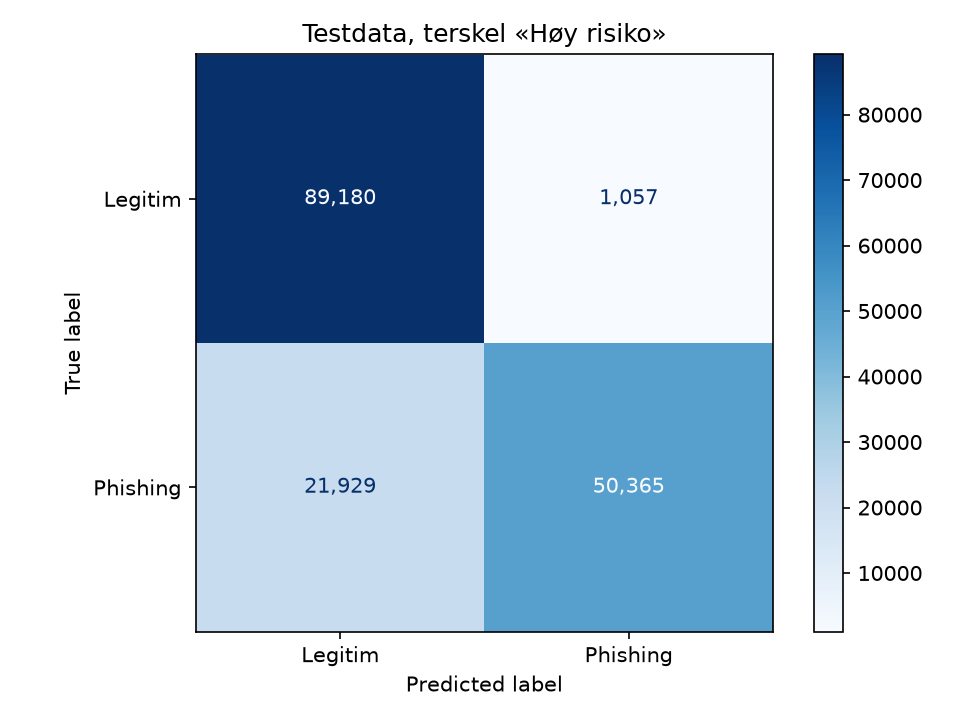

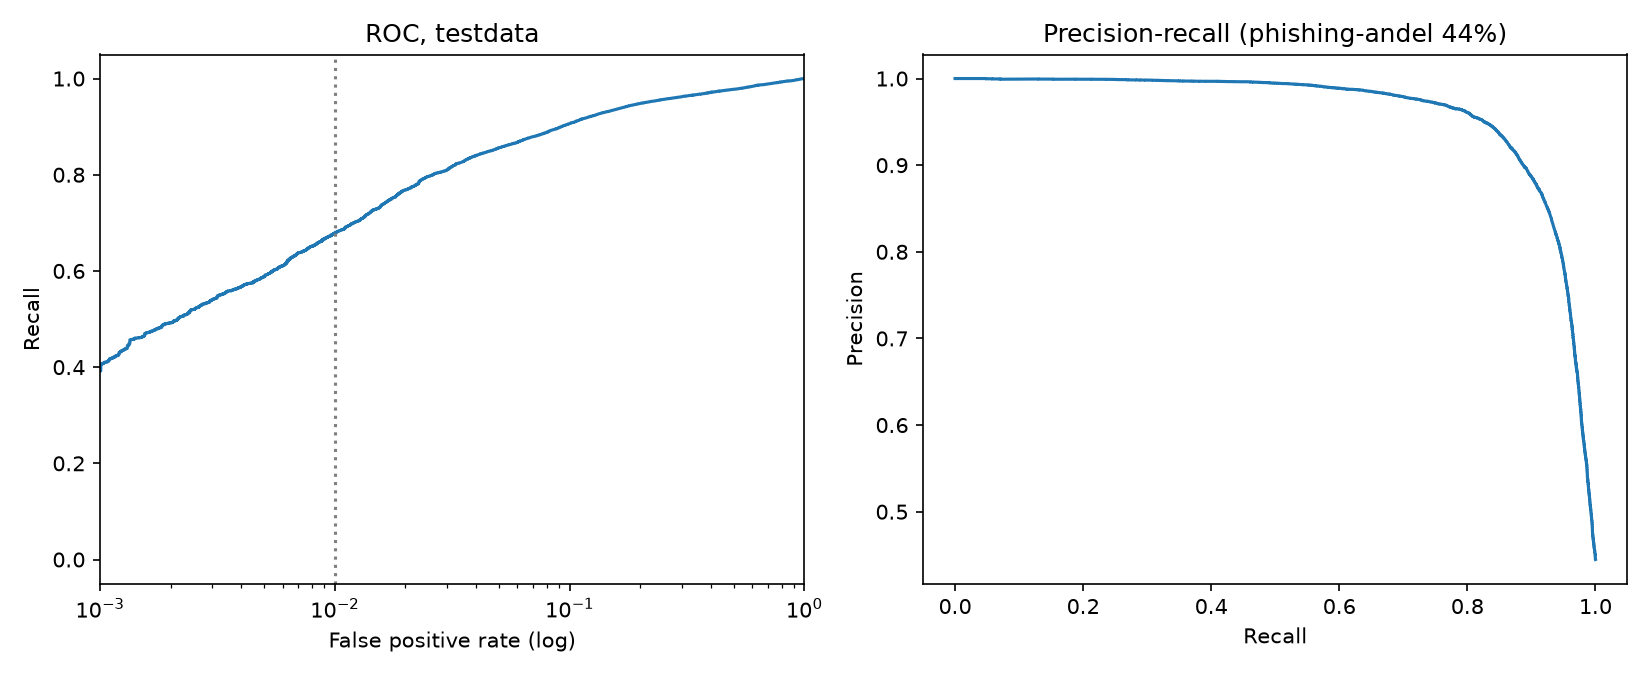

In [10]:
te = json.load(open('../reports/test_metrics.json'))
v1 = json.load(open('../reports/archive_v1/test_metrics.json'))
display(pd.DataFrame({'v1 (kjøring 1)': {'ROC-AUC': v1['test']['roc_auc'], 'recall Høy': v1['test']['at_t_high']['recall'], 'FPR Høy': v1['test']['at_t_high']['fpr'], 'presisjon 1 %': v1['benchmarks']['1%']['precision_mean'], 'presisjon 5 %': v1['benchmarks']['5%']['precision_mean']},
                      'v2 (kjøring 2)': {'ROC-AUC': te['test']['roc_auc'], 'recall Høy': te['test']['at_t_high']['recall'], 'FPR Høy': te['test']['at_t_high']['fpr'], 'presisjon 1 %': te['benchmarks']['1%']['precision_mean'], 'presisjon 5 %': te['benchmarks']['5%']['precision_mean']}}).round(4))
display(te['test'], te['benchmarks'], pd.DataFrame(te['per_month']).T, te['unseen_sites'], te['robustness'], te['shorteners_not_scored'])
display(Image('../reports/figures/test_confusion_matrix.png')); display(Image('../reports/figures/test_roc_pr.png'))

## 6. Simulert overvåking
Testmånedene spilles av i rekkefølge som om de var ny trafikk. Regel for ny trening: FPR over 2 ganger val-FPR, eller recall mer enn 0,10 under val-recall.

,month,n,share_high,share_suspicious,mean_score,fpr_high,recall_high,retrain_trigger
0,2025-09,31351,0.058180,0.052056,0.076834,0.011266,0.362378,True
1,2025-10,110731,0.324751,0.106700,0.342572,0.011846,0.695109,False
2,2025-11,19484,0.698830,0.115890,0.700860,0.008617,0.781719,False
3,2025-12,965,0.022798,0.043523,0.043337,0.022798,NaN,True


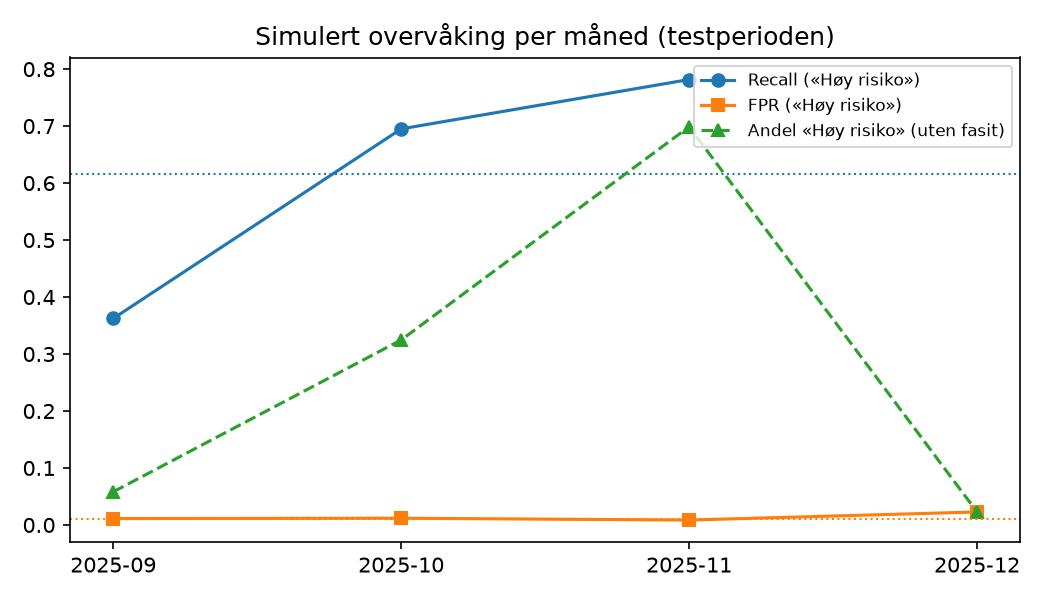

In [11]:
mo = json.load(open('../reports/monitoring.json'))
display(pd.DataFrame(mo['months']))
display(Image('../reports/figures/monitoring.png'))

## 7. Kvalitativ sjekk på norske nettsteder
Den **skjulte listen** ble frosset før v2-arbeidet og kjørt bare etter at v2 var låst. **Utviklingslisten** avdekket merkenavn-feilen i v1 og har derfor påvirket utviklingen.

In [12]:
display(Markdown(open('../reports/sanity_check.md').read()))

# Kvalitativ sjekk av modell v2

## Skjult liste (frosset før v2-iterasjonen, kjørt etter at v2 var låst, aldri brukt til tuning)

| Type | URL | Bånd | Score |
|---|---|---|---|
| Legitim | `https://www[.]dagbladet[.]no/` | Lav risiko | 9 |
| Legitim | `https://www[.]e24[.]no/` | Mistenkelig | 27 |
| Legitim | `https://www[.]bt[.]no/` | Lav risiko | 4 |
| Legitim | `https://www[.]tv2[.]no/nyheter` | Høy risiko | 71 |
| Legitim | `https://www[.]nordea[.]no/privat/` | Lav risiko | 11 |
| Legitim | `https://www[.]storebrand[.]no/` | Lav risiko | 8 |
| Legitim | `https://www[.]gjensidige[.]no/privat/forsikring` | Lav risiko | 2 |
| Legitim | `https://www[.]if[.]no/` | Lav risiko | 2 |
| Legitim | `https://www[.]lanekassen[.]no/` | Lav risiko | 8 |
| Legitim | `https://www[.]udir[.]no/` | Lav risiko | 4 |
| Legitim | `https://www[.]ntnu[.]no/studier` | Mistenkelig | 15 |
| Legitim | `https://www[.]uio[.]no/` | Lav risiko | 1 |
| Legitim | `https://www[.]oslo[.]kommune[.]no/` | Lav risiko | 0 |
| Legitim | `https://www[.]bergen[.]kommune[.]no/` | Lav risiko | 0 |
| Legitim | `https://www[.]politiet[.]no/` | Lav risiko | 9 |
| Legitim | `https://www[.]brreg[.]no/` | Mistenkelig | 15 |
| Legitim | `https://www[.]statensvegvesen[.]no/` | Lav risiko | 8 |
| Legitim | `https://www[.]xxl[.]no/` | Lav risiko | 3 |
| Legitim | `https://www[.]power[.]no/` | Lav risiko | 6 |
| Legitim | `https://www[.]zalando[.]no/` | Lav risiko | 7 |
| Legitim | `https://www[.]kiwi[.]no/` | Lav risiko | 2 |
| Legitim | `https://www[.]obos[.]no/` | Lav risiko | 1 |
| Legitim | `https://www[.]prisjakt[.]no/` | Mistenkelig | 16 |
| Legitim | `https://www[.]sas[.]no/` | Lav risiko | 1 |
| Legitim | `https://www[.]flytoget[.]no/` | Mistenkelig | 14 |
| Legitim | `https://www[.]ikea[.]com/no/no/` | Lav risiko | 0 |
| Legitim | `https://www[.]spotify[.]com/no/` | Lav risiko | 0 |
| Legitim | `https://www[.]microsoft[.]com/nb-no/` | Lav risiko | 0 |
| Legitim | `https://www[.]apple[.]com/no/` | Lav risiko | 0 |
| Legitim | `https://www[.]netflix[.]com/no/` | Lav risiko | 0 |
| Konstruert phishing | `https://nordea-kunde-verifisering[.]top/login` | Høy risiko | 99 |
| Konstruert phishing | `http://bankid-fornyelse[.]info/oppdater` | Høy risiko | 96 |
| Konstruert phishing | `https://lanekassen-tilbakebetaling[.]click/refund` | Høy risiko | 99 |
| Konstruert phishing | `https://gjensidige[.]no[.]claim-payment[.]xyz/` | Høy risiko | 92 |
| Konstruert phishing | `http://45[.]13[.]22[.]101/storebrand/secure/login[.]php` | Høy risiko | 99 |
| Konstruert phishing | `https://politiet-bot-betaling[.]shop/` | Høy risiko | 97 |
| Konstruert phishing | `https://netflix-account-suspended[.]vercel[.]app/update` | Høy risiko | 99 |
| Konstruert phishing | `https://apple-icloud-locked[.]web[.]app/unlock` | Høy risiko | 99 |
| Konstruert phishing | `https://xn--nrdea-ppa[.]com/login` | Høy risiko | 80 |
| Konstruert phishing | `https://postnord-pakke-toll[.]buzz/betal` | Høy risiko | 94 |

## Utviklingsliste (avdekket merkenavn-feilen i v1, har derfor påvirket utviklingen)

| Type | URL | Bånd | Score |
|---|---|---|---|
| Legitim | `https://www[.]nrk[.]no` | Lav risiko | 3 |
| Legitim | `https://www[.]nrk[.]no/nyheter/` | Mistenkelig | 13 |
| Legitim | `https://www[.]vg[.]no` | Lav risiko | 4 |
| Legitim | `https://www[.]vg[.]no/nyheter` | Mistenkelig | 16 |
| Legitim | `https://www[.]aftenposten[.]no/` | Lav risiko | 8 |
| Legitim | `https://www[.]dnb[.]no/` | Lav risiko | 1 |
| Legitim | `https://www[.]dnb[.]no/privat/kort` | Lav risiko | 0 |
| Legitim | `https://www[.]vipps[.]no/` | Lav risiko | 8 |
| Legitim | `https://www[.]posten[.]no/sporing` | Lav risiko | 1 |
| Legitim | `https://www[.]nav[.]no/` | Lav risiko | 1 |
| Legitim | `https://www[.]skatteetaten[.]no/person/skatt/` | Lav risiko | 6 |
| Legitim | `https://www[.]hvl[.]no/` | Lav risiko | 4 |
| Legitim | `https://www[.]hvl[.]no/studier/` | Mistenkelig | 17 |
| Legitim | `https://www[.]uib[.]no/` | Lav risiko | 2 |
| Legitim | `https://www[.]finn[.]no/` | Lav risiko | 2 |
| Legitim | `https://www[.]finn[.]no/bap/forsale/search[.]html` | Mistenkelig | 32 |
| Legitim | `https://www[.]regjeringen[.]no/no/id4/` | Mistenkelig | 22 |
| Legitim | `https://www[.]helsenorge[.]no/` | Lav risiko | 9 |
| Legitim | `https://www[.]yr[.]no/nb` | Lav risiko | 7 |
| Legitim | `https://www[.]altinn[.]no/` | Lav risiko | 6 |
| Legitim | `https://www[.]bankid[.]no/` | Lav risiko | 3 |
| Legitim | `https://www[.]elkjop[.]no/` | Lav risiko | 7 |
| Legitim | `https://www[.]komplett[.]no/` | Mistenkelig | 14 |
| Legitim | `https://www[.]sparebank1[.]no/nb/bank/privat[.]html` | Mistenkelig | 47 |
| Legitim | `https://www[.]telenor[.]no/` | Lav risiko | 7 |
| Legitim | `https://www[.]ruter[.]no/` | Lav risiko | 6 |
| Legitim | `https://www[.]vy[.]no/` | Lav risiko | 4 |
| Legitim | `https://www[.]norwegian[.]no/` | Lav risiko | 9 |
| Legitim | `https://www[.]husqvarna[.]com/no/` | Lav risiko | 2 |
| Legitim | `https://github[.]com/` | Lav risiko | 3 |
| Konstruert phishing | `http://secure-dnb-login[.]verify-account[.]xyz/bankid` | Høy risiko | 99 |
| Konstruert phishing | `https://vipps-refund-claim[.]webflow[.]io/` | Høy risiko | 99 |
| Konstruert phishing | `http://192[.]168[.]10[.]5/posten/tracking[.]php` | Høy risiko | 99 |
| Konstruert phishing | `https://posten-no-sporing-pakke[.]top/betal` | Høy risiko | 99 |
| Konstruert phishing | `https://nav-utbetaling-bekreft[.]com/login` | Høy risiko | 95 |
| Konstruert phishing | `https://dnb[.]no[.]secure-auth-session[.]click/` | Høy risiko | 99 |
| Konstruert phishing | `https://xn--pypal-4ve[.]com/signin` | Mistenkelig | 50 |
| Konstruert phishing | `http://apple-id-unlock-support[.]info/account/verify` | Høy risiko | 99 |
| Konstruert phishing | `https://helsenorge-innlogging[.]shop/bankid` | Høy risiko | 99 |
| Konstruert phishing | `https://microsoft365-mailbox-upgrade[.]vercel[.]app/` | Høy risiko | 99 |
